# 3.  Codificación de variables

Conjunto de datos: titanic (incluido en seaborn)

Este conjunto de datos es excelente para trabajar con variables categóricas.

In [2]:
# Importar librerías necesarias
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [3]:
# Cargar el conjunto de datos
data = sns.load_dataset('titanic')

In [4]:
# Visualizar las primeras filas
print("Conjunto de datos Titanic:")
data.head()

Conjunto de datos Titanic:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [ ]:
# Seleccionar columnas categóricas
categorical_cols = ['sex', 'embarked', 'class']

In [6]:
# Codificar con LabelEncoder
label_encoder = LabelEncoder()
data['sex_label'] = label_encoder.fit_transform(data['sex'])

In [7]:
# Codificar con OneHotEncoder
onehot_encoder = pd.get_dummies(data['embarked'], prefix='embarked')

In [8]:
# Combinar con el conjunto original
data = pd.concat([data, onehot_encoder], axis=1)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre LabelEncoder y OneHotEncoder?

In [9]:
df_label = data.copy()

le_sex      = LabelEncoder()
le_embarked = LabelEncoder()
le_class    = LabelEncoder()

df_label['sex']      = le_sex.fit_transform(df_label['sex'])
df_label['embarked'] = le_embarked.fit_transform(df_label['embarked'])
df_label['class']    = le_class.fit_transform(df_label['class'])

print("=== LabelEncoder ===")
print(df_label.head())
print("\nColumnas:", df_label.columns.tolist())
print("Mapeos:")
print("  sex:     ", dict(zip(le_sex.classes_,      le_sex.transform(le_sex.classes_))))
print("  embarked:", dict(zip(le_embarked.classes_, le_embarked.transform(le_embarked.classes_))))
print("  class:   ", dict(zip(le_class.classes_,    le_class.transform(le_class.classes_))))

=== LabelEncoder ===
   survived  pclass  sex   age  sibsp  parch     fare  embarked  class    who  \
0         0       3    1  22.0      1      0   7.2500         2      2    man   
1         1       1    0  38.0      1      0  71.2833         0      0  woman   
2         1       3    0  26.0      0      0   7.9250         2      2  woman   
3         1       1    0  35.0      1      0  53.1000         2      0  woman   
4         0       3    1  35.0      0      0   8.0500         2      2    man   

   adult_male deck  embark_town alive  alone  sex_label  embarked_C  \
0        True  NaN  Southampton    no  False          1       False   
1       False    C    Cherbourg   yes  False          0        True   
2       False  NaN  Southampton   yes   True          0       False   
3       False    C  Southampton   yes  False          0       False   
4        True  NaN  Southampton    no   True          1       False   

   embarked_Q  embarked_S  
0       False        True  
1       F

In [10]:
df_ohe = data.copy()

ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
encoded = ohe.fit_transform(df_ohe[['sex', 'embarked', 'class']])

ohe_df = pd.DataFrame(
    encoded,
    columns=ohe.get_feature_names_out(['sex', 'embarked', 'class']),
    index=df_ohe.index
)

df_ohe = pd.concat([df_ohe.drop(columns=['sex', 'embarked', 'class']), ohe_df], axis=1)

print("=== OneHotEncoder ===")
print(df_ohe.head())
print("\nColumnas:", df_ohe.columns.tolist())

=== OneHotEncoder ===
   survived  pclass   age  sibsp  parch     fare    who  adult_male deck  \
0         0       3  22.0      1      0   7.2500    man        True  NaN   
1         1       1  38.0      1      0  71.2833  woman       False    C   
2         1       3  26.0      0      0   7.9250  woman       False  NaN   
3         1       1  35.0      1      0  53.1000  woman       False    C   
4         0       3  35.0      0      0   8.0500    man        True  NaN   

   embark_town  ... embarked_S  sex_female  sex_male  embarked_C  embarked_Q  \
0  Southampton  ...       True         0.0       1.0         0.0         0.0   
1    Cherbourg  ...      False         1.0       0.0         1.0         0.0   
2  Southampton  ...       True         1.0       0.0         0.0         0.0   
3  Southampton  ...       True         1.0       0.0         0.0         0.0   
4  Southampton  ...       True         0.0       1.0         0.0         0.0   

   embarked_S  embarked_nan  class_First

In [12]:
print("=== Estadísticas LabelEncoder ===")
print(df_label[['sex', 'embarked', 'class']].describe().round(3))

print("\n=== Estadísticas OneHotEncoder ===")
print(df_ohe.filter(regex='sex_|embarked_|class_').describe().round(3))

=== Estadísticas LabelEncoder ===
           sex  embarked    class
count  891.000   891.000  891.000
mean     0.648     1.539    1.309
std      0.478     0.794    0.836
min      0.000     0.000    0.000
25%      0.000     1.000    1.000
50%      1.000     2.000    2.000
75%      1.000     2.000    2.000
max      1.000     3.000    2.000

=== Estadísticas OneHotEncoder ===
       sex_label  sex_female  sex_male  embarked_C  embarked_Q  embarked_S  \
count    891.000     891.000   891.000     891.000     891.000     891.000   
mean       0.648       0.352     0.648       0.189       0.086       0.723   
std        0.478       0.478     0.478       0.391       0.281       0.448   
min        0.000       0.000     0.000       0.000       0.000       0.000   
25%        0.000       0.000     0.000       0.000       0.000       0.000   
50%        1.000       0.000     1.000       0.000       0.000       1.000   
75%        1.000       1.000     1.000       0.000       0.000       1.000   


### 2. Crea una gráfica de barras comparando las frecuencias de 'sex' antes y después de la codificación con LabelEncoder.

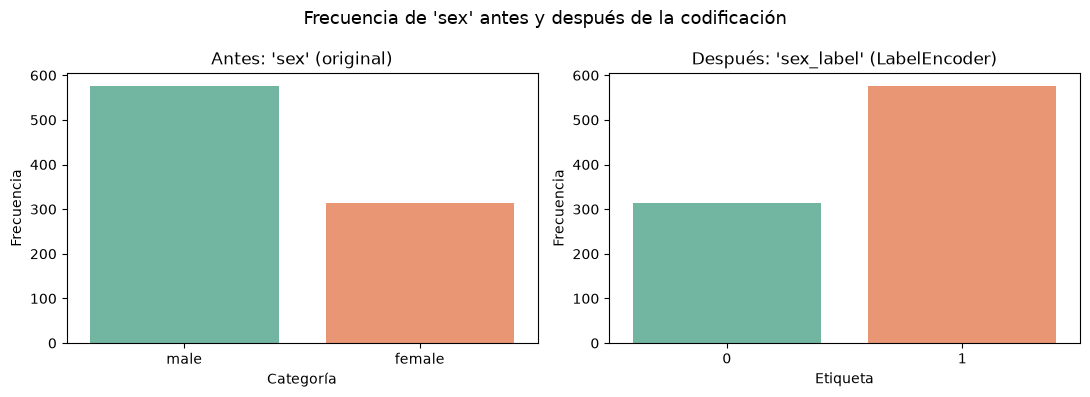

In [14]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(data=data, x='sex', ax=axes[0],
              hue='sex', palette='Set2', legend=False)
axes[0].set_title("Antes: 'sex' (original)")
axes[0].set_xlabel('Categoría')
axes[0].set_ylabel('Frecuencia')

sns.countplot(data=data, x='sex_label', ax=axes[1],
              hue='sex_label', palette='Set2', legend=False)
axes[1].set_title("Después: 'sex_label' (LabelEncoder)")
axes[1].set_xlabel('Etiqueta')
axes[1].set_ylabel('Frecuencia')

plt.suptitle("Frecuencia de 'sex' antes y después de la codificación", fontsize=13)
plt.tight_layout()
plt.show()

### 3. Utiliza OneHotEncoder para codificar la columna 'class'. ¿Qué ventajas tiene este enfoque frente a LabelEncoder?

In [15]:
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
encoded = ohe.fit_transform(data[['class']])

# Nombres de las nuevas columnas
cols_ohe = ohe.get_feature_names_out(['class'])
print("Columnas generadas:", cols_ohe)

# DataFrame con las columnas one-hot
df_ohe = pd.DataFrame(encoded, columns=cols_ohe, index=data.index)

# Unir al dataset
data_ohe = pd.concat([data.drop(columns='class'), df_ohe], axis=1)

print(data_ohe.head())
print(data_ohe.filter(regex='class_').head(8))

Columnas generadas: ['class_First' 'class_Second' 'class_Third']
   survived  pclass     sex   age  sibsp  parch     fare embarked    who  \
0         0       3    male  22.0      1      0   7.2500        S    man   
1         1       1  female  38.0      1      0  71.2833        C  woman   
2         1       3  female  26.0      0      0   7.9250        S  woman   
3         1       1  female  35.0      1      0  53.1000        S  woman   
4         0       3    male  35.0      0      0   8.0500        S    man   

   adult_male  ...  embark_town alive  alone  sex_label  embarked_C  \
0        True  ...  Southampton    no  False          1       False   
1       False  ...    Cherbourg   yes  False          0        True   
2       False  ...  Southampton   yes   True          0       False   
3       False  ...  Southampton   yes  False          0       False   
4        True  ...  Southampton    no   True          1       False   

   embarked_Q  embarked_S  class_First  class_Secon

### 4. Si quisieras aplicar un modelo de aprendizaje automático, ¿qué tipo de codificación elegirías para las variables categóricas? Explica tu respuesta.


Depende de dos factores:

El tipo de variable (nominal vs ordinal, y su cardinalidad).

El tipo de modelo (lineal/distancia vs árboles).

No hay una única respuesta correcta, pero sí una guía clara